# Which candidates correlate (+/−) with IL-8 (CXCL8) across all conditions

For every candidate, build its log2FC vector across the shared conditions
(Cd/Co/Bt vs Mock, the pairwise contrasts, and the butyrate doses) and correlate it with CXCL8's
vector. **High positive r = co-regulated with IL-8** (same conditional brake); **negative r =
moves opposite**. Same extraction as `17`/`19` (feat_df for A06, lfc-difference for pairwise,
A04 DE for butyrate). Kernel: any pandas/scipy/matplotlib env.

In [1]:
import pandas as pd, numpy as np, os, re
from pathlib import Path
from scipy import stats
import matplotlib as mpl, matplotlib.pyplot as plt
A06 = Path(os.environ.get('A06_PROJ', str(Path.home()/'Projects_shared/epithelial_coinfection-model_WORKING')))
A04 = Path(os.environ.get('A04_PROJ', str(Path.home()/'Projects_shared/DECIDE_A04_CdiffOrganoid_Butyrate')))
FIG = A04/'results/figures'; FIG.mkdir(parents=True, exist_ok=True)
mpl.rcParams.update({'font.family':'sans-serif','font.sans-serif':['Helvetica','Arial','DejaVu Sans'],
  'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':140,'savefig.dpi':300,'savefig.bbox':'tight'})

feat_path=None
for p in ['analysis/causal_v6/full_feature_matrix.csv','analysis/causal_v4/full_feature_matrix.csv','analysis/causal_v2/full_feature_matrix.csv']:
    if (A06/p).exists(): feat_path=A06/p; break
feat_df=pd.read_csv(feat_path,index_col='gene'); print('feat_df:',feat_path,feat_df.shape)

_cache={}
def A04tab(fn):
    if fn in _cache: return _cache[fn]
    f=A04/'results/tables'/fn
    d=None
    if f.exists():
        d=pd.read_csv(f,index_col=0)
        for col in ['gene_name','symbol','Gene','gene']:
            if col in d.columns: d=d.set_index(col); break
        d.index=[re.sub(r'\..*','',str(i)) for i in d.index]
    _cache[fn]=d; return d
def A04lfc(fn,g):
    d=A04tab(fn)
    if d is None or g not in d.index: return np.nan
    return float(d.loc[g].get('log2FoldChange',np.nan))

# condition vector for a gene (order fixed); pairwise from feat_df differences
def vec(g):
    def gl(c): return float(feat_df.loc[g,f'lfc_{c}']) if g in feat_df.index else np.nan
    return np.array([
        gl('Cd'), gl('Co'), gl('Bt'),                    # infection contexts
        gl('Bt')-gl('Cd'), gl('Cd')-gl('Co'), gl('Bt')-gl('Co'),   # pairwise
        A04lfc('DE_Butyrate_5v0_Mock.csv',g), A04lfc('DE_Butyrate_10v0_Mock.csv',g),
        A04lfc('DE_Butyrate_5v0_Cd.csv',g),   A04lfc('DE_Butyrate_10v0_Cd.csv',g),
    ], float)
COND=['Cd/Mock','Co/Mock','Bt/Mock','Bt-Cd','Cd-Co','Bt-Co','But5.M','But10.M','But5.Cd','But10.Cd']

feat_df: /home/job37yv/Projects_shared/epithelial_coinfection-model_WORKING/analysis/causal_v6/full_feature_matrix.csv (766, 43)


In [2]:
CANDIDATES = ['CXCL1','CXCL2','CXCL3','CCL20','BIRC3',
              'HSPA5','CALR','WFS1','CRYAB','BAG3','CLU',
              'XBP1','ATF4','ATF6','EIF2AK3','GSK3B',
              'HSF1','RELA','NFKB1','REL','RELB','JUN','IRF1','STAT3','MYC','CEBPB','CEBPD',
              'IRAK2','TRAF6','IKBKE','TAB2','TNFAIP3','NFKBIZ',
              'DDX58','IFIH1','ZBP1','RIPK2','TLR2',
              'SP1','PCK1','CYP11A1','SLC22A4']

ref=vec('CXCL8')
res=[]
for g in CANDIDATES:
    v=vec(g)
    ok=~(np.isnan(ref)|np.isnan(v))
    if ok.sum()<4:  # need enough shared points
        res.append((g,np.nan,np.nan,int(ok.sum()))); continue
    r,p=stats.pearsonr(ref[ok],v[ok])
    res.append((g,r,p,int(ok.sum())))
R=pd.DataFrame(res,columns=['gene','r','p','n']).sort_values('r',ascending=False).reset_index(drop=True)
print('Correlation of each candidate with CXCL8 (across conditions):')
print(R.round(3).to_string())

Correlation of each candidate with CXCL8 (across conditions):
       gene      r      p   n
0     CXCL2  0.976  0.000  10
1     CXCL1  0.970  0.000  10
2     CXCL3  0.966  0.000  10
3   TNFAIP3  0.960  0.000  10
4     IFIH1  0.940  0.000  10
5      RELB  0.928  0.000  10
6     BIRC3  0.928  0.000  10
7     CCL20  0.915  0.000  10
8     IRAK2  0.858  0.001  10
9     IKBKE  0.842  0.002  10
10      JUN  0.809  0.005  10
11    RIPK2  0.806  0.005  10
12     TLR2  0.773  0.227   4
13    NFKB1  0.769  0.009  10
14    CEBPB  0.757  0.011  10
15     ATF4  0.719  0.019  10
16     XBP1  0.691  0.027  10
17     RELA  0.654  0.040  10
18   NFKBIZ  0.648  0.352   4
19      REL  0.561  0.092  10
20     HSF1  0.553  0.098  10
21  CYP11A1  0.531  0.278   6
22    STAT3  0.494  0.146  10
23     IRF1  0.485  0.156  10
24     ATF6  0.472  0.168  10
25    CEBPD  0.419  0.581   4
26      SP1  0.370  0.292  10
27    GSK3B  0.286  0.423  10
28    HSPA5  0.274  0.444  10
29    TRAF6  0.273  0.445  10
30      

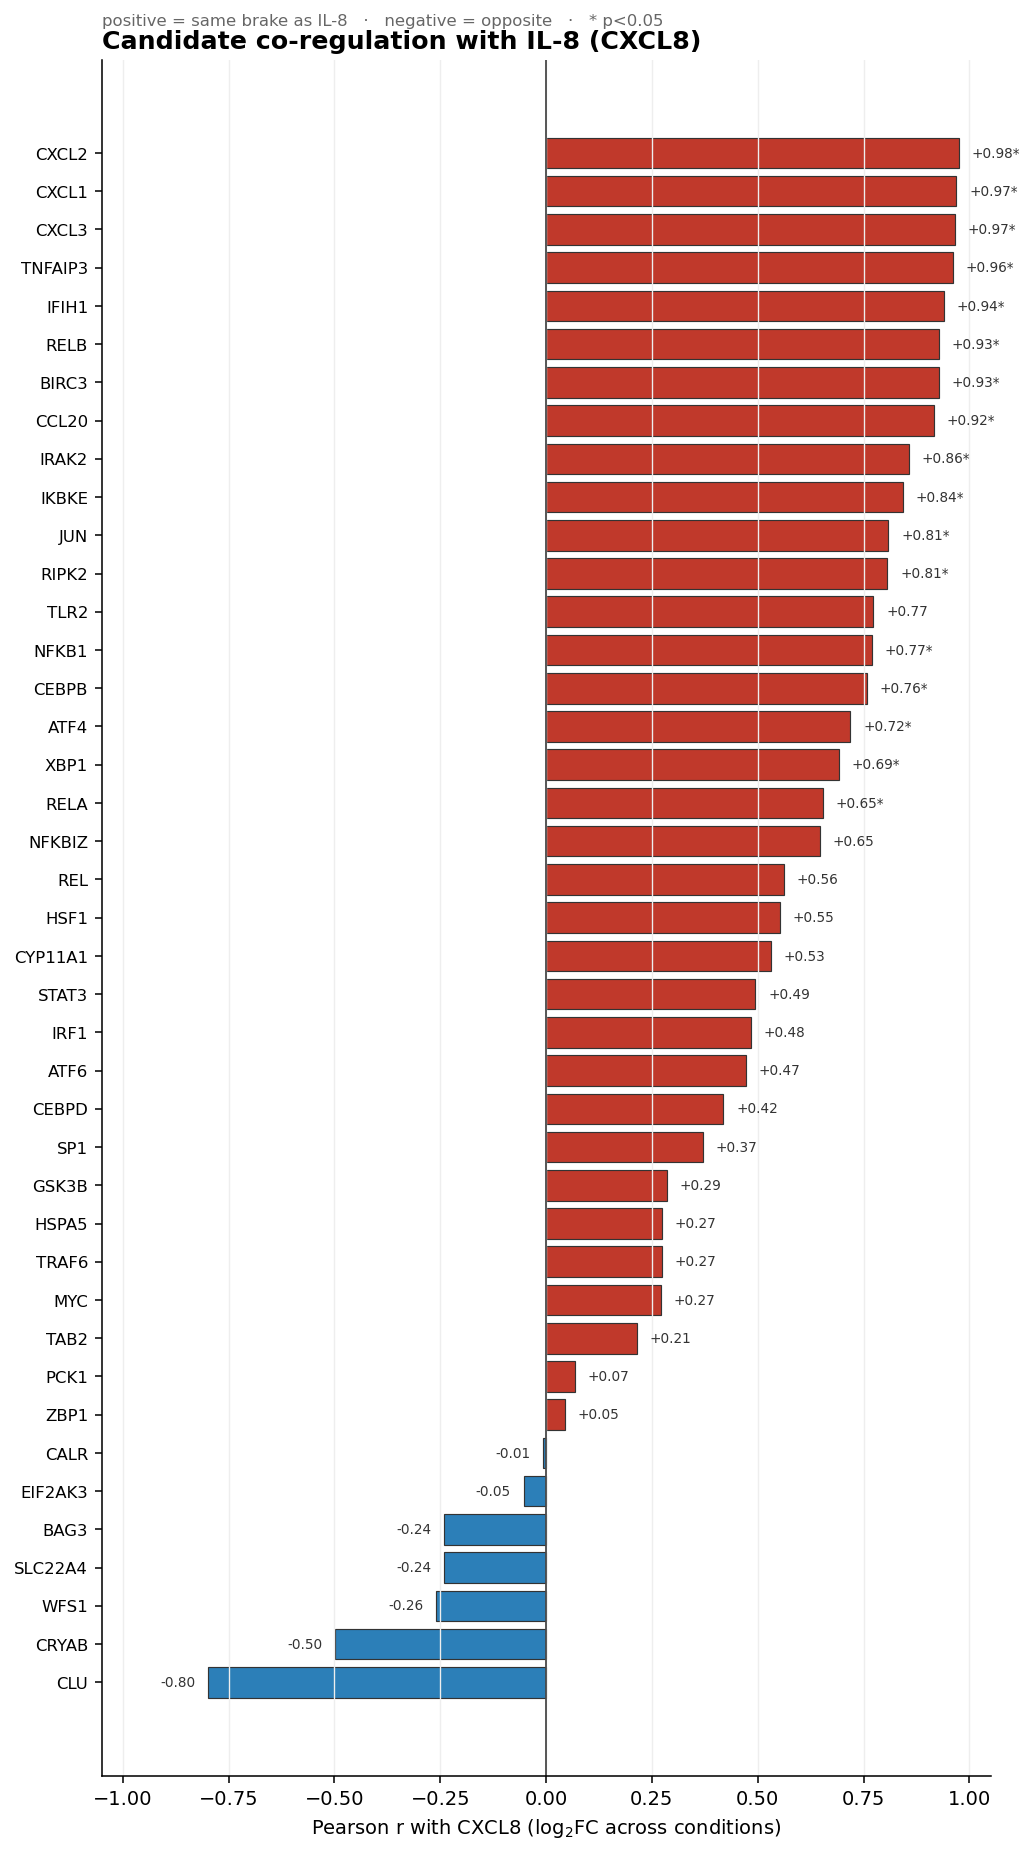

wrote /home/job37yv/Projects_shared/DECIDE_A04_CdiffOrganoid_Butyrate/results/figures/candidate_correlation_with_CXCL8.png


In [3]:
# ---- plot: ranked correlation bar ----
d=R.dropna(subset=['r']).copy()
n=len(d); y=np.arange(n)
colors=['#c0392b' if v>=0 else '#2c7fb8' for v in d.r]
fig,ax=plt.subplots(figsize=(7.5, max(4,0.30*n+1)))
ax.barh(y, d.r, color=colors, edgecolor='#333', lw=.6)
ax.axvline(0,color='#444',lw=.9)
ax.set_yticks(y); ax.set_yticklabels(d.gene, fontsize=8.5)
ax.invert_yaxis()
ax.set_xlabel('Pearson r with CXCL8 (log$_2$FC across conditions)', fontsize=10)
ax.set_xlim(-1.05,1.05)
for yi,(_,r) in zip(y,d.iterrows()):
    star='*' if (not np.isnan(r.p) and r.p<0.05) else ''
    ax.text(r.r+(0.03 if r.r>=0 else -0.03), yi, f'{r.r:+.2f}{star}',
            va='center', ha='left' if r.r>=0 else 'right', fontsize=7, color='#333')
ax.set_title('Candidate co-regulation with IL-8 (CXCL8)', fontsize=13, fontweight='bold', loc='left')
ax.text(0,1.02,'positive = same brake as IL-8   ·   negative = opposite   ·   * p<0.05',
        transform=ax.transAxes, fontsize=8.5, color='#666')
ax.grid(axis='x', color='#eee', lw=.7)
plt.tight_layout(); fig.savefig(FIG/'candidate_correlation_with_CXCL8.png'); plt.show()
print('wrote',FIG/'candidate_correlation_with_CXCL8.png')

## Reading it
- **r near +1** → the gene tracks IL-8 across every condition: up with infection, braked by butyrate
  the same way. Expect the chemokine outputs (CXCL1/2/3, CCL20) here — same NF-κB conditional brake.
- **r near −1** → moves opposite to IL-8 (e.g. genes that go *up* where IL-8 goes down).
- **r near 0** → decoupled — different regulation (candidate for the chaperone arm, which is coupled
  in the infected baseline but not butyrate-braked the same way).
- `n` = number of shared (non-missing) conditions used; low n = gene missing from some tables.
- This is correlation of the *condition-profile* (10 contrasts), a compact way to ask 'which genes
  share IL-8's brake'. It is not per-sample expression correlation (that needs the count matrix).